# Performance Attribution (Brinson)

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Decomposes a portfolio's excess return over its benchmark into allocation (over- or under-weighting sectors), selection (picking better or worse securities within sectors) and interaction effects, using the Brinson-Fachler model. A waterfall walks from the benchmark return to the portfolio return; a second panel shows the effects by sector, so you can see which decisions added or cost value.

## When to use

- Explain why a fund beat or lagged its benchmark over a period
- Separate the value of sector calls from stock picking
- Report to investment committees or clients

## Avoid when

- Multi-period attribution without a proper linking method (effects do not simply add across periods)
- Strategies that are not managed by sector weights (use factor attribution instead)

## Alternatives

- Factor exposure / factor attribution chart
- Table of contribution to return by holding

## Design tips

- State the model: Brinson-Fachler allocation = (w_p − w_b)(r_b,i − R_b), selection = w_b (r_p,i − r_b,i), interaction = (w_p − w_b)(r_p,i − r_b,i)
- Show totals as dark anchor bars and effects as floating bars
- Effects must sum exactly to the excess return; print the check

## Example

A simulated one-year attribution for a fund with six sectors against its benchmark. Not investment advice.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
sectors = ["Technology", "Financials", "Health care", "Industrials", "Energy", "Consumer"]
df = pd.DataFrame({
    "w_p": [0.32, 0.12, 0.14, 0.14, 0.10, 0.18],    # portfolio weights
    "w_b": [0.25, 0.16, 0.13, 0.15, 0.08, 0.23],    # benchmark weights
    "r_p": [0.245, 0.098, 0.071, 0.132, 0.012, 0.085],   # portfolio sector returns
    "r_b": [0.228, 0.104, 0.052, 0.118, 0.061, 0.079],   # benchmark sector returns
}, index=sectors)
df

,w_p,w_b,r_p,r_b
Technology,0.32,0.25,0.245,0.228
Financials,0.12,0.16,0.098,0.104
Health care,0.14,0.13,0.071,0.052
Industrials,0.14,0.15,0.132,0.118
Energy,0.10,0.08,0.012,0.061
Consumer,0.18,0.23,0.085,0.079


### Plot

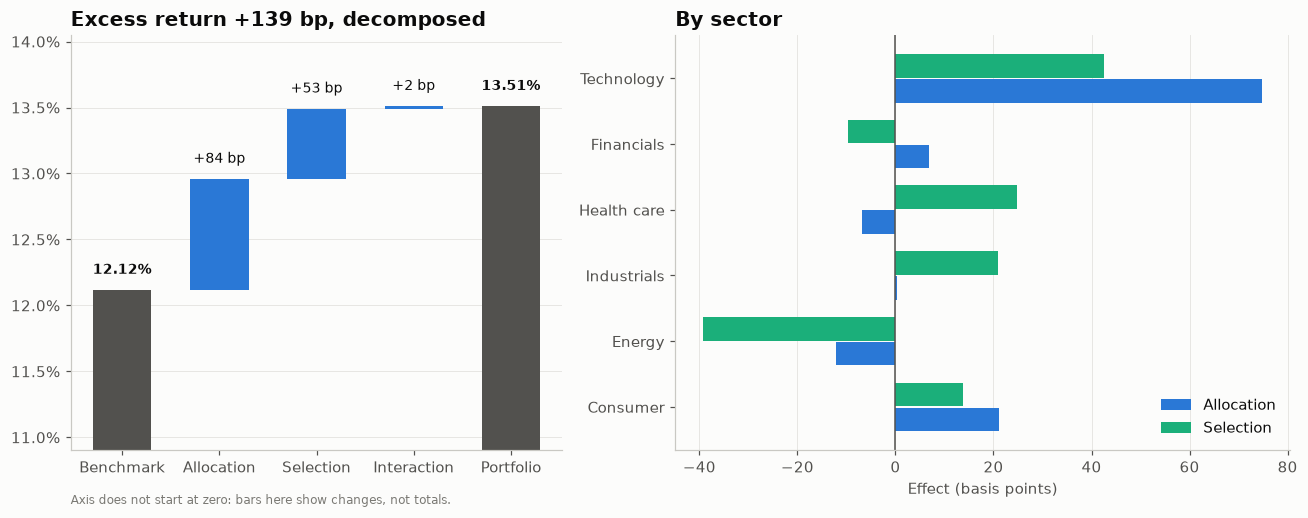

In [3]:
R_b, R_p = (df.w_b * df.r_b).sum(), (df.w_p * df.r_p).sum()
df["allocation"] = (df.w_p - df.w_b) * (df.r_b - R_b)
df["selection"] = df.w_b * (df.r_p - df.r_b)
df["interaction"] = (df.w_p - df.w_b) * (df.r_p - df.r_b)
effects = df[["allocation", "selection", "interaction"]].sum()
assert np.isclose(effects.sum(), R_p - R_b)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
steps = [("Benchmark", R_b, "total"), ("Allocation", effects["allocation"], "fx"),
         ("Selection", effects["selection"], "fx"), ("Interaction", effects["interaction"], "fx"),
         ("Portfolio", R_p, "total")]
level = 0
for i, (lab, v, kind) in enumerate(steps):
    if kind == "total":
        ax.bar(i, v, color="#52514e", width=0.6)
        ax.text(i, v + 0.001, f"{v:.2%}", ha="center", va="bottom", fontsize=9, weight="bold")
        level = v
    else:
        ax.bar(i, v, bottom=level, color=PALETTE[0] if v >= 0 else PALETTE[1], width=0.6)
        ax.text(i, max(level, level + v) + 0.001, f"{v * 1e4:+.0f} bp", ha="center", va="bottom", fontsize=9)
        level += v
ax.set_xticks(range(len(steps)), [s[0] for s in steps])
lo = min(R_b, R_p) * 0.9
ax.set_ylim(lo, max(R_b, R_p) * 1.04)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title(f"Excess return {(R_p - R_b) * 1e4:+.0f} bp, decomposed")
ax.text(0.0, -0.13, "Axis does not start at zero: bars here show changes, not totals.",
        transform=ax.transAxes, fontsize=8, color="#7a7974")
ax.grid(axis="x", visible=False)

by = df[["allocation", "selection"]] * 1e4
y = np.arange(len(by))
ax2.barh(y + 0.19, by["allocation"], height=0.36, color=PALETTE[0], label="Allocation")
ax2.barh(y - 0.19, by["selection"], height=0.36, color=PALETTE[2], label="Selection")
ax2.axvline(0, color="#52514e", linewidth=1)
ax2.set_yticks(y, by.index)
ax2.invert_yaxis()
ax2.set_xlabel("Effect (basis points)")
ax2.set_title("By sector")
ax2.legend(loc="lower right")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Left: start from the benchmark return, add each effect (blue adds value, orange subtracts) and arrive at the portfolio return. Right: the same allocation and selection effects split by sector, showing, for example, that the technology overweight helped while stock selection in energy hurt.

---
Standalone script: [`brinson_attribution.py`](brinson_attribution.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)